# Análisis: preguntas de negocio y arquetipos de clientes

Este notebook usa las tablas limpias generadas por 01_limpieza.ipynb.

## 1. Carga de datos limpios

In [1]:
from pathlib import Path
import pandas as pd

RAIZ = Path.cwd().parent
PROC = RAIZ / "data" / "processed"
FIGS = RAIZ / "reports" / "figures"
DATA = RAIZ / "data"

archivos = ["customers", "orders", "order_items", "products"]
faltantes = [a for a in archivos if not (PROC / f"{a}.csv").exists()]
assert not faltantes, f"Faltan archivos en {PROC}: {faltantes}. Ejecuta primero 01_limpieza.ipynb"

customers   = pd.read_csv(PROC / "customers.csv",
                          parse_dates=["fecha_registro", "fecha_nacimiento", "primera_compra", "cliente_desde"])
orders      = pd.read_csv(PROC / "orders.csv", parse_dates=["fecha"])
order_items = pd.read_csv(PROC / "order_items.csv")
products    = pd.read_csv(PROC / "products.csv", parse_dates=["fecha_lanzamiento"])
stores = pd.read_csv(DATA / "stores.csv")  

FECHA_CORTE = pd.Timestamp("2026-09-30")

for nombre, df in {"customers": customers, "orders": orders, "order_items": order_items,
                   "products": products, "stores": stores}.items():
    print(f"{nombre}: {df.shape[0]} filas")

customers: 3005 filas
orders: 22651 filas
order_items: 47641 filas
products: 240 filas
stores: 5 filas


## 2. Tabla base de ventas

Se unen las líneas de venta con su orden, su producto y su cliente, y se calcula la venta neta de cada línea. Se aplican las definiciones de la limpieza:
- Solo cuentan como venta las órdenes completadas.
- Venta neta = cantidad × precio_unitario × (1 − descuento_pct / 100).
- El total de ventas de la marca incluye todas las ventas completadas; el análisis por cliente usa solo las órdenes atribuibles a un cliente registrado, sin cuentas internas.

In [3]:
ventas = (order_items
    .merge(orders, on="order_id", how="inner")
    .merge(products[["sku", "coleccion", "categoria", "fecha_lanzamiento"]], on="sku", how="left")
    .merge(customers[["customer_id", "cuenta_interna"]], on="customer_id", how="left")
    .merge(stores.rename(columns={"nombre": "tienda"}), on="tienda_id", how="left"))

ventas = ventas[ventas["es_venta"]].copy()
ventas["venta_neta"] = ventas["cantidad"] * ventas["precio_unitario"] * (1 - ventas["descuento_pct"] / 100)
ventas["cuenta_interna"] = ventas["cuenta_interna"].fillna(False).astype(bool)

# Ventas que se pueden asignar a un cliente real
ventas_cli = ventas[ventas["cliente_atribuible"] & ~ventas["cuenta_interna"]]

total_marca = ventas["venta_neta"].sum()
total_cli = ventas_cli["venta_neta"].sum()

print(f"Ventas netas de la marca: {total_marca:,.0f} MXN ({ventas['order_id'].nunique():,} órdenes)")
print(f"Ventas atribuibles a clientes: {total_cli:,.0f} MXN ({total_cli / total_marca:.1%})")
print(f"Clientes con al menos una compra: {ventas_cli['customer_id'].nunique():,}")

Ventas netas de la marca: 45,033,143 MXN (21,297 órdenes)
Ventas atribuibles a clientes: 42,247,804 MXN (93.8%)
Clientes con al menos una compra: 2,877


## 3. Pregunta 1: ¿quiénes se interesan por las nuevas colecciones?

### Verificación previa: ventas anteriores al lanzamiento del producto (P3)

Para medir el interés por lo nuevo hay que comparar la fecha de cada venta con la fecha de lanzamiento del producto. Antes se revisa que esa comparación tenga sentido: un producto no debería venderse antes de su lanzamiento.

In [7]:
ventas["dias_desde_lanz"] = (ventas["fecha"] - ventas["fecha_lanzamiento"]).dt.days
antes = ventas["dias_desde_lanz"] < 0

print("Líneas vendidas antes del lanzamiento:", antes.sum(), f"({antes.sum() / ventas['fecha_lanzamiento'].notna().sum():.2%})")
print("Clientes distintos:", ventas.loc[antes, "customer_id"].nunique())

ids_antes = ventas.loc[antes, "customer_id"].dropna().unique()
evento = customers.set_index("customer_id")["nota_evento_lanzamiento"]
print("De esos clientes, con nota de evento de lanzamiento:", int(evento.reindex(ids_antes).fillna(False).sum()), "de", int(evento.sum()))

(ventas[antes].groupby("coleccion")["dias_desde_lanz"]
   .agg(lineas="count", dias_min="min", dias_mediana="median", dias_max="max")
   .sort_values("lineas", ascending=False))

Líneas vendidas antes del lanzamiento: 1886 (5.84%)
Clientes distintos: 669
De esos clientes, con nota de evento de lanzamiento: 5 de 15


,lineas,dias_min,dias_mediana,dias_max
coleccion,,,,
PV24,1043,-45.0,-29.0,-1.0
OI26,291,-938.0,-403.0,-1.0
PV26,238,-770.0,-362.5,-1.0
OI25,151,-593.0,-240.0,-14.0
PV25,101,-379.0,-213.0,-1.0
OI24,62,-231.0,-108.5,-6.0


**Idea principal:** hay productos que aparecen vendidos antes de su fecha de lanzamiento, algo que no debería pasar. Son 1.886 líneas (5,8% de las ventas con colección), de 669 clientes. Esto significa que, para esas ventas, la colección que indica el catálogo no es confiable.

**Cómo leer la tabla:** dias_desde_lanz es la diferencia entre la fecha de la venta y la fecha de lanzamiento del producto. Un valor negativo significa que la venta ocurrió antes del lanzamiento.
- dias_min: la venta más lejana al lanzamiento (por ejemplo, −938 = vendida 938 días antes de que el producto existiera).
- dias_max: la venta más cercana al lanzamiento (−1 = vendida un día antes).
- dias_mediana: el valor típico; la mitad de las ventas anticipadas está por encima de ese valor y la otra mitad por debajo.

**Hay dos situaciones distintas:**

1. **PV24: 1.043 líneas, entre 1 y 45 días antes. Tiene explicación.** Los datos de órdenes empiezan el 2024-01-01, pero la primera colección del catálogo (PV24) se lanzó el 2024-02-15. Lo que se vendió en esas seis semanas eran productos de la temporada anterior, que no está en el catálogo; por eso aparecen con códigos de PV24.

2. **Resto de colecciones: 843 líneas, hasta 938 días antes. No tiene explicación de negocio.** Por ejemplo, hay productos de OI26 (lanzada en agosto de 2026) vendidos desde enero de 2024. Son casos aislados: las 291 líneas de OI26 están repartidas en más de dos años y equivalen a menos del 1% de lo que vendió la marca en ese periodo. Si fuera un comportamiento real, se verían ventas constantes de esos productos; en cambio, aparecen de forma esporádica. Lo más probable es un error en la fecha o en el SKU de esas órdenes.

**No es una preventa:** si fuera acceso anticipado para clientes especiales, serían pocos clientes y concentrados en las colecciones nuevas. En cambio, son 669 clientes, en todas las colecciones, y solo 5 de ellos asistieron a un evento de lanzamiento.

In [8]:
ventas["coleccion_valida"] = ventas["coleccion"].notna() & (
    ventas["coleccion"].eq("BASICOS") | (ventas["dias_desde_lanz"] >= 0))

# ventas_cli se recalcula para que también tenga las columnas nuevas
ventas_cli = ventas[ventas["cliente_atribuible"] & ~ventas["cuenta_interna"]]

print("Líneas con colección válida:", ventas["coleccion_valida"].sum(), "de", len(ventas))

Líneas con colección válida: 42849 de 44789


**Tratamiento:** se crea la bandera coleccion_valida. Las ventas anteriores al lanzamiento se mantienen en el total de ventas, pero no cuentan como compras de una colección.

**Impacto si no se corrige:** se contarían como compradores de una colección a clientes que compraron antes de que existiera. Además, todas las ventas de enero y febrero de 2024 se asignarían a PV24, inflando esa colección.

### ¿Cuánto dura el efecto de un lanzamiento?

Antes de definir la ventana de "compra de lanzamiento", se revisa cómo se distribuyen las ventas de cada colección según los días transcurridos desde su lanzamiento.

In [12]:
temp = ventas_cli[ventas_cli["coleccion_valida"] & (ventas_cli["coleccion"] != "BASICOS")]
semana = (temp["dias_desde_lanz"] // 7).clip(upper=26)

tabla_semanas = (temp.groupby(semana)["venta_neta"].sum()
                 .div(temp["venta_neta"].sum()).mul(100)
                 .rename("% ventas").to_frame())
tabla_semanas["% acumulado"] = tabla_semanas["% ventas"].cumsum()
tabla_semanas.index.name = "semana desde el lanzamiento"

tabla_semanas.round(1).head(26)

,% ventas,% acumulado
semana desde el lanzamiento,,
0.0,9.7,9.7
1.0,9.6,19.4
2.0,10.3,29.7
3.0,3.4,33.1
4.0,2.7,35.8
5.0,2.7,38.5
6.0,2.5,41.0
7.0,2.4,43.4
8.0,2.5,45.9


En las semanas 0, 1 y 2 se vende cerca del 10% de las ventas de temporada en cada una; desde la semana 3 el aporte cae a entre 2% y 3,5% semanal y se mantiene estable. Las primeras 3 semanas acumulan el 29,7% de las ventas de una colección, más que las 8 semanas siguientes juntas.

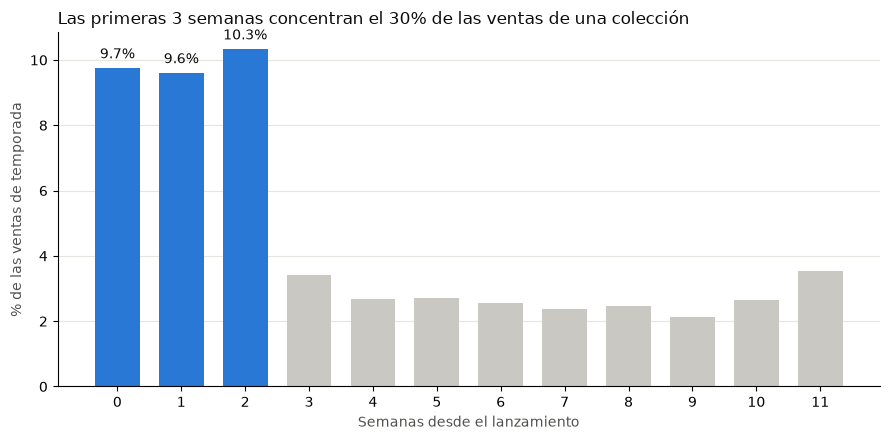

In [10]:
import matplotlib.pyplot as plt

temp = ventas_cli[ventas_cli["coleccion_valida"] & (ventas_cli["coleccion"] != "BASICOS")]
semana = temp["dias_desde_lanz"] // 7
dist = (temp.groupby(semana)["venta_neta"].sum() / temp["venta_neta"].sum() * 100).loc[0:11]

VENTANA_SEMANAS = 3
colores = ["#2a78d6" if s < VENTANA_SEMANAS else "#c9c8c2" for s in dist.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(dist.index, dist.values, color=colores, width=0.7)

# Etiqueta solo en las semanas del lanzamiento
for b, s in zip(barras, dist.index):
    if s < VENTANA_SEMANAS:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{b.get_height():.1f}%",
                ha="center", fontsize=10, color="#0b0b0b")

ax.set_title(f"Las primeras {VENTANA_SEMANAS} semanas concentran el "
             f"{dist.loc[:VENTANA_SEMANAS - 1].sum():.0f}% de las ventas de una colección",
             loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Semanas desde el lanzamiento", color="#52514e")
ax.set_ylabel("% de las ventas de temporada", color="#52514e")
ax.set_xticks(dist.index)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGS / "q1_ventana_lanzamiento.png", dpi=200, bbox_inches="tight")
plt.show()

La caída es abrupta y ocurre justo en la semana 3: el efecto del lanzamiento dura unas 3 semanas, no se desvanece poco a poco. Por eso se define la ventana de lanzamiento en 21 días: una compra de un producto de temporada dentro de ese periodo indica interés por lo nuevo; una compra posterior es una compra de temporada normal.

### Criterio

Un cliente se interesa por las nuevas colecciones si compra productos de temporada (no BASICOS) durante la ventana de lanzamiento: los primeros 21 días después de que sale la colección (semanas 0, 1 y 2). Comprar un producto meses después de su lanzamiento no muestra interés por lo nuevo; comprarlo en el lanzamiento, sí.

- **Interesado:** compró en el lanzamiento de 1 colección.
- **Muy interesado:** compró en el lanzamiento de 2 o más colecciones; el interés se repite y no es casualidad.

In [13]:
VENTANA_DIAS = 21

col = ventas_cli[ventas_cli["coleccion_valida"] & (ventas_cli["coleccion"] != "BASICOS")].copy()
col["compra_lanzamiento"] = (col["dias_desde_lanz"] >= 0) & (col["dias_desde_lanz"] < VENTANA_DIAS)

# Por cliente: en cuántos lanzamientos compró y cuánto gastó en ellos
lanz = (col[col["compra_lanzamiento"]].groupby("customer_id")
        .agg(colecciones_lanz=("coleccion", "nunique"), venta_lanz=("venta_neta", "sum")))

clientes = ventas_cli.groupby("customer_id").agg(venta_total=("venta_neta", "sum"))
clientes = clientes.join(lanz).fillna({"colecciones_lanz": 0, "venta_lanz": 0})

clientes["nivel_novedad"] = pd.cut(clientes["colecciones_lanz"], bins=[-1, 0, 1, float("inf")],
                                   labels=["Sin interés", "Interesado", "Muy interesado"])

resumen_q1 = (clientes.groupby("nivel_novedad", observed=True)
              .agg(clientes=("venta_total", "size"), venta_total=("venta_total", "sum"), venta_lanz=("venta_lanz", "sum")))
resumen_q1["% clientes"] = (resumen_q1["clientes"] / resumen_q1["clientes"].sum() * 100).round(1)
resumen_q1["% ventas marca"] = (resumen_q1["venta_total"] / total_marca * 100).round(1)
resumen_q1

,clientes,venta_total,venta_lanz,% clientes,% ventas marca
nivel_novedad,,,,,
Sin interés,2158,16230693.00,0.00,75.0,36.0
Interesado,238,2499352.95,637329.20,8.3,5.6
Muy interesado,481,23517758.45,8553895.85,16.7,52.2


In [14]:
validacion = clientes.join(customers.set_index("customer_id")[["nota_evento_lanzamiento"]])
print(pd.crosstab(validacion["nivel_novedad"], validacion["nota_evento_lanzamiento"],
                  margins=True, margins_name="Total"))

nota_evento_lanzamiento  False  True  Total
nivel_novedad                              
Sin interés               2144    14   2158
Interesado                 237     1    238
Muy interesado             481     0    481
Total                     2862    15   2877


In [15]:
ids_evento = customers.loc[customers["nota_evento_lanzamiento"], "customer_id"]
ev = ventas_cli[ventas_cli["customer_id"].isin(ids_evento)]

print("Clientes con nota de evento que compraron algo:", ev["customer_id"].nunique(), "de", len(ids_evento))
print("Compras de temporada por momento respecto al lanzamiento:")
momento = pd.cut(ev["dias_desde_lanz"], bins=[-10_000, -1, 20, 10_000],
                 labels=["Antes del lanzamiento", "Ventana (0–20 días)", "Después de la ventana"])
print(momento.value_counts().to_string())
print("\nLíneas de BASICOS:", (ev["coleccion"] == "BASICOS").sum())

Clientes con nota de evento que compraron algo: 15 de 15
Compras de temporada por momento respecto al lanzamiento:
dias_desde_lanz
Después de la ventana    54
Antes del lanzamiento    10
Ventana (0–20 días)       3

Líneas de BASICOS: 113


### Validación con las notas del CRM

Se esperaba que los 15 clientes con la nota "Registro en evento de lanzamiento" aparecieran como interesados o muy interesados. No es así: 14 quedaron en "Sin interés". Al revisar sus compras, los 15 sí compran, pero principalmente productos BASICOS (113 líneas), y sus compras de temporada ocurren casi siempre después de la ventana de lanzamiento (54 líneas, frente a 3 dentro de ella).

**Conclusión:** la nota indica que el cliente se registró durante un evento, no que compre novedades. El criterio basado en el comportamiento de compra es más confiable que una nota de texto libre presente en solo 15 clientes.

**Oportunidad:** los eventos de lanzamiento están captando clientes de básicos. Los 481 clientes "muy interesados", que generan el 52% de las ventas de la marca, serían el público natural para invitar a esos eventos.

### Respuesta a la pregunta 1

- 481 clientes (16,7%) son "muy interesados": compraron en el lanzamiento de 2 o más colecciones. Generan el 52,2% de las ventas de la marca, y no solo compran en el lanzamiento: de sus 23,5 millones de MXN, unos 8,6 millones corresponden a la ventana de lanzamiento y el resto a compras durante la temporada.
- 238 clientes (8,3%) son "interesados": compraron en un solo lanzamiento; generan el 5,6% de las ventas.
- 2.158 clientes (75%) no compran en los lanzamientos y generan el 36% de las ventas.

Las novedades atraen a un grupo pequeño de clientes que concentra más de la mitad del negocio.

## 4. Pregunta 2: ¿quiénes compran de forma recurrente?

Para definir "recurrente" se revisa primero cada cuánto vuelven a comprar los clientes. En moda no se compra con la regularidad de una suscripción mensual, así que el criterio debe salir del comportamiento real.

### ¿Cada cuánto vuelven a comprar?

Para cada cliente se ordenan sus compras por fecha y se calcula cuántos días pasan entre una compra y la siguiente. Se cuenta una compra por orden, no por producto.

In [18]:
compras = (ventas_cli.drop_duplicates("order_id")[["customer_id", "order_id", "fecha"]]
           .sort_values(["customer_id", "fecha"]))
compras["dias_entre"] = compras.groupby("customer_id")["fecha"].diff().dt.days

n_compras = compras.groupby("customer_id").size()
print("Compras por cliente (todo el historial):")
print(n_compras.describe()[["min", "25%", "50%", "75%", "max"]].to_string())
print(f"\nClientes con una sola compra: {(n_compras == 1).sum()} ({(n_compras == 1).mean():.1%})")

print("\nDías entre compras:")
print(compras["dias_entre"].describe()[["25%", "50%", "75%"]].round(0).to_string())

Compras por cliente (todo el historial):
min     1.0
25%     2.0
50%     3.0
75%     9.0
max    36.0

Clientes con una sola compra: 633 (22.0%)

Días entre compras:
25%    31.0
50%    42.0
75%    60.0


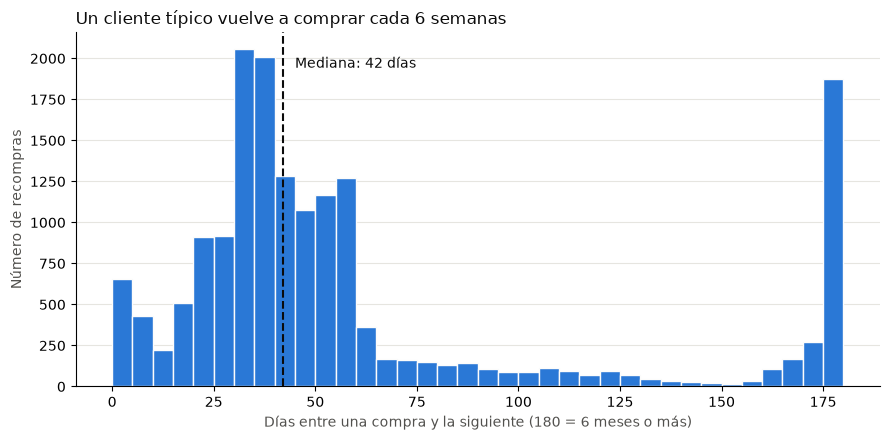

In [19]:
dias = compras["dias_entre"].dropna()
mediana = dias.median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(dias.clip(upper=180), bins=36, color="#2a78d6", edgecolor="#fcfcfb", linewidth=1)
ax.axvline(mediana, color="#0b0b0b", linewidth=1.5, linestyle="--")
ax.text(mediana + 3, ax.get_ylim()[1] * 0.9, f"Mediana: {mediana:.0f} días", color="#0b0b0b", fontsize=10)

ax.set_title("Un cliente típico vuelve a comprar cada 6 semanas", loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Días entre una compra y la siguiente (180 = 6 meses o más)", color="#52514e")
ax.set_ylabel("Número de recompras", color="#52514e")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGS / "q2_dias_entre_compras.png", dpi=200, bbox_inches="tight")
plt.show()

Un cliente típico vuelve a comprar cada 42 días (unas 6 semanas); la mitad de las recompras ocurre entre 31 y 60 días después de la anterior. Pero el comportamiento es muy desigual: la mitad de los clientes hizo 3 compras o menos en todo el historial, mientras que el 25% más activo hizo 9 o más (hasta 36). Además, el 22% compró una sola vez.

### ¿Cuántas veces compró cada cliente en el último año?

La recurrencia debe ser actual: un cliente que compraba seguido en 2024 y no ha vuelto no es recurrente hoy. Por eso se cuentan las compras de los últimos 12 meses (del 2025-10-01 al 2026-09-30) y se revisa cómo se reparten los clientes.

In [20]:
ultimo_anio = compras[compras["fecha"] > FECHA_CORTE - pd.DateOffset(months=12)]
compras_12m = ultimo_anio.groupby("customer_id").size().reindex(n_compras.index, fill_value=0)

print(compras_12m.value_counts().sort_index().to_string())

0     850
1     526
2     427
3     217
4     105
5      88
6     129
7     153
8     155
9      55
10     30
11     59
12     48
13     25
14      8
15      2


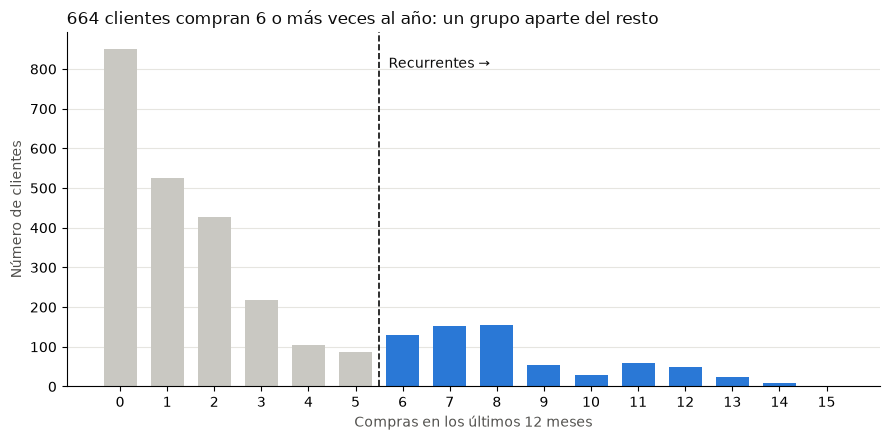

In [21]:
dist12 = compras_12m.value_counts().sort_index()
UMBRAL = 6
colores = ["#2a78d6" if n >= UMBRAL else "#c9c8c2" for n in dist12.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(dist12.index, dist12.values, color=colores, width=0.7)
ax.axvline(UMBRAL - 0.5, color="#0b0b0b", linewidth=1.2, linestyle="--")
ax.text(UMBRAL - 0.3, ax.get_ylim()[1] * 0.9, "Recurrentes →", color="#0b0b0b", fontsize=10)

recurrentes = (compras_12m >= UMBRAL).sum()
ax.set_title(f"{recurrentes} clientes compran 6 o más veces al año: un grupo aparte del resto",
             loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Compras en los últimos 12 meses", color="#52514e")
ax.set_ylabel("Número de clientes", color="#52514e")
ax.set_xticks(dist12.index)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGS / "q2_compras_ultimo_anio.png", dpi=200, bbox_inches="tight")
plt.show()

La distribución muestra dos grupos: el número de clientes baja de forma continua entre 0 y 5 compras al año (de 850 a 88), y a partir de 6 compras vuelve a subir (129, 153 y 155 clientes con 6, 7 y 8 compras). El "valle" en 4–5 compras separa a la mayoría que compra poco de un grupo con un ritmo de compra constante.

### Criterio

El umbral se fija en 6 compras al año, por dos razones que coinciden: es donde empieza el segundo grupo de clientes, y equivale a comprar cada 2 meses o más seguido, en línea con el tiempo típico entre compras (42 días de mediana).

- **Recurrente:** 6 o más compras en los últimos 12 meses.
- **Ocasional:** 2 a 5 compras.
- **Inactivo o de una sola compra:** 0 o 1 compra.

In [22]:
clientes["compras_total"] = n_compras
clientes["compras_12m"] = compras_12m

clientes["nivel_recurrencia"] = pd.cut(clientes["compras_12m"], bins=[-1, 1, 5, float("inf")],
                                       labels=["Inactivo / una compra", "Ocasional", "Recurrente"])

resumen_q2 = (clientes.groupby("nivel_recurrencia", observed=True)
              .agg(clientes=("venta_total", "size"), venta_total=("venta_total", "sum"),
                   compras_12m_prom=("compras_12m", "mean")))
resumen_q2["% clientes"] = (resumen_q2["clientes"] / resumen_q2["clientes"].sum() * 100).round(1)
resumen_q2["% ventas marca"] = (resumen_q2["venta_total"] / total_marca * 100).round(1)
resumen_q2.round(1)

,clientes,venta_total,compras_12m_prom,% clientes,% ventas marca
nivel_recurrencia,,,,,
Inactivo / una compra,1376,3707847.6,0.4,47.8,8.2
Ocasional,837,9613352.2,2.8,29.1,21.3
Recurrente,664,28926604.6,8.4,23.1,64.2


### Respuesta a la pregunta 2

- 664 clientes (23,1%) son recurrentes: compran 6 o más veces al año (8,4 en promedio) y generan el 64,2% de las ventas de la marca.
- 837 clientes (29,1%) son ocasionales: 2 a 5 compras al año; generan el 21,3% de las ventas.
- 1.376 clientes (47,8%) están inactivos o compraron una sola vez** en el último año; generan el 8,2% de las ventas, casi todo por compras anteriores.

Uno de cada cuatro clientes sostiene casi dos tercios del negocio, y casi la mitad de la base registrada no compra con regularidad: es el grupo con mayor potencial de reactivación.

## 5. Pregunta 3: ¿quiénes son los clientes de mayor valor?

No hay datos de costo ni de margen, así que el valor se mide como las ventas netas acumuladas de cada cliente en todo el historial. Se usa todo el historial (y no solo el último año) para que esta pregunta mida algo distinto de la recurrencia: cuánto ha aportado el cliente, no qué tan seguido compra hoy.

### ¿Qué tan concentradas están las ventas?

Se ordenan los clientes de mayor a menor gasto y se calcula qué porcentaje de las ventas acumulan los primeros.

In [23]:
orden = clientes["venta_total"].sort_values(ascending=False)
pct_clientes = pd.Series(range(1, len(orden) + 1)) / len(orden) * 100
pct_ventas = orden.cumsum().values / orden.sum() * 100

for p in [10, 20, 30, 50]:
    corte = int(len(orden) * p / 100)
    print(f"El {p}% de clientes con más gasto genera el {pct_ventas[corte - 1]:.1f}% de las ventas a clientes")

El 10% de clientes con más gasto genera el 52.4% de las ventas a clientes
El 20% de clientes con más gasto genera el 69.7% de las ventas a clientes
El 30% de clientes con más gasto genera el 81.4% de las ventas a clientes
El 50% de clientes con más gasto genera el 93.1% de las ventas a clientes


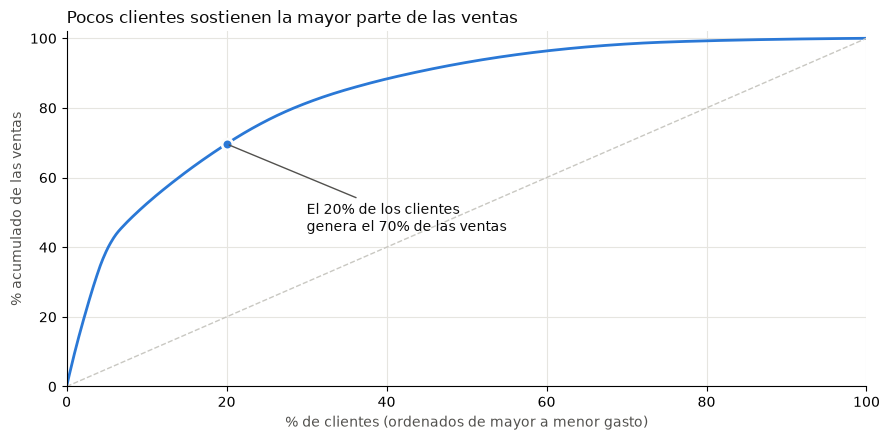

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(pct_clientes, pct_ventas, color="#2a78d6", linewidth=2)
ax.plot([0, 100], [0, 100], color="#c9c8c2", linewidth=1, linestyle="--")

top20 = pct_ventas[int(len(orden) * 0.2) - 1]
ax.scatter([20], [top20], color="#2a78d6", s=60, zorder=3, edgecolor="#fcfcfb", linewidth=2)
ax.annotate(f"El 20% de los clientes\ngenera el {top20:.0f}% de las ventas", xy=(20, top20),
            xytext=(30, top20 - 25), fontsize=10, color="#0b0b0b",
            arrowprops=dict(arrowstyle="-", color="#52514e"))

ax.set_title("Pocos clientes sostienen la mayor parte de las ventas", loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("% de clientes (ordenados de mayor a menor gasto)", color="#52514e")
ax.set_ylabel("% acumulado de las ventas", color="#52514e")
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGS / "q3_pareto.png", dpi=200, bbox_inches="tight")
plt.show()

Las ventas están muy concentradas: el 10% de clientes que más gasta genera el 52% de las ventas atribuibles, el 20% genera el 70% y la mitad que menos gasta solo aporta el 7%. La curva sube casi en vertical hasta cerca del 7% de los clientes: existe un núcleo pequeño con un gasto muy superior al del resto.

### Criterio

- **Alto valor:** el 20% de clientes con mayores ventas netas acumuladas (el punto donde se concentra cerca del 70% de las ventas, en línea con el principio de Pareto).
- **Valor medio:** el siguiente 30%.
- **Valor bajo:** el 50% con menores ventas.

In [29]:
clientes["ticket_prom"] = clientes["venta_total"] / clientes["compras_total"]

rango = clientes["venta_total"].rank(ascending=False, pct=True)   # 0,01 = top 1%
clientes["nivel_valor"] = pd.cut(rango, bins=[0, 0.2, 0.5, 1], labels=["Alto valor", "Valor medio", "Valor bajo"])

resumen_q3 = (clientes.groupby("nivel_valor", observed=True)
              .agg(clientes=("venta_total", "size"), venta_total=("venta_total", "sum"),
                   compras_total=("compras_total", "sum"),
                   gasto_prom=("venta_total", "mean"), compras_prom=("compras_total", "mean")))
resumen_q3["ticket_prom"] = resumen_q3["venta_total"] / resumen_q3["compras_total"]
resumen_q3["% clientes"] = (resumen_q3["clientes"] / resumen_q3["clientes"].sum() * 100).round(1)
resumen_q3["% ventas marca"] = (resumen_q3["venta_total"] / total_marca * 100).round(1)
resumen_q3.drop(columns="compras_total").round(0)

,clientes,venta_total,gasto_prom,compras_prom,ticket_prom,% clientes,% ventas marca
nivel_valor,,,,,,,
Alto valor,575,29428063.0,51179.0,19.0,2634.0,20.0,65.0
Valor medio,863,9893864.0,11464.0,7.0,1661.0,30.0,22.0
Valor bajo,1439,2925878.0,2033.0,2.0,1088.0,50.0,6.0


In [30]:
pd.crosstab(clientes["nivel_valor"], clientes["nivel_recurrencia"], margins=True, margins_name="Total")

nivel_recurrencia,Inactivo / una compra,Ocasional,Recurrente,Total
nivel_valor,,,,
Alto valor,0,132,443,575
Valor medio,198,449,216,863
Valor bajo,1178,256,5,1439
Total,1376,837,664,2877


### Respuesta a la pregunta 3

- 575 clientes (20%) son de alto valor y generan el 65% de las ventas de la marca. Gastan en promedio 51.179 MXN en 19 compras.
- 863 clientes (30%) son de valor medio: 22% de las ventas, con 11.464 MXN en 7 compras en promedio.
- 1.439 clientes (50%) son de valor bajo: 6% de las ventas, con 2.033 MXN en 2 compras en promedio.

**¿De dónde viene el valor?** El gasto total es el número de compras por el ticket promedio, y ambos crecen con el nivel de valor. Un cliente de alto valor compra unas 9,5 veces más que uno de valor bajo (19 vs. 2 compras) y además gasta 2,4 veces más por compra (2.634 vs. 1.088 MXN). La frecuencia es el factor principal, pero el ticket también contribuye: son dos factores distintos para el CRM, una para que el cliente vuelva más seguido y otra para que lleve más en cada compra.

**Cruce con la recurrencia:**
- 443 de los 575 clientes de alto valor son recurrentes: el núcleo del negocio.
- 132 clientes de alto valor son solo ocasionales este año: aportaron mucho, pero su ritmo de compra bajó. Es el grupo prioritario para una campaña de retención.
- 216 clientes de valor medio ya son recurrentes: compran seguido, pero con menor gasto; tienen potencial para subir a alto valor.
- Ningún cliente de alto valor está inactivo.

## 6. Resumen de las tres preguntas

En las tres preguntas aparece el mismo patrón: un grupo minoritario de clientes concentra la mayor parte de las ventas. Como un mismo cliente puede pertenecer a varios grupos, primero se mide cuánto se superponen.

In [32]:
es_novedad = clientes["nivel_novedad"].eq("Muy interesado")
es_recurrente = clientes["nivel_recurrencia"].eq("Recurrente")
es_alto = clientes["nivel_valor"].eq("Alto valor")

nucleo = es_novedad & es_recurrente & es_alto
alguno = es_novedad | es_recurrente | es_alto

for nombre, m in [("En los tres grupos (núcleo)", nucleo), ("En al menos uno", alguno)]:
    print(f"{nombre}: {m.sum()} clientes ({m.mean():.1%}) | "
          f"{clientes.loc[m, 'venta_total'].sum() / total_marca:.1%} de las ventas de la marca")

En los tres grupos (núcleo): 175 clientes (6.1%) | 38.9% de las ventas de la marca
En al menos uno: 973 clientes (33.8%) | 77.7% de las ventas de la marca


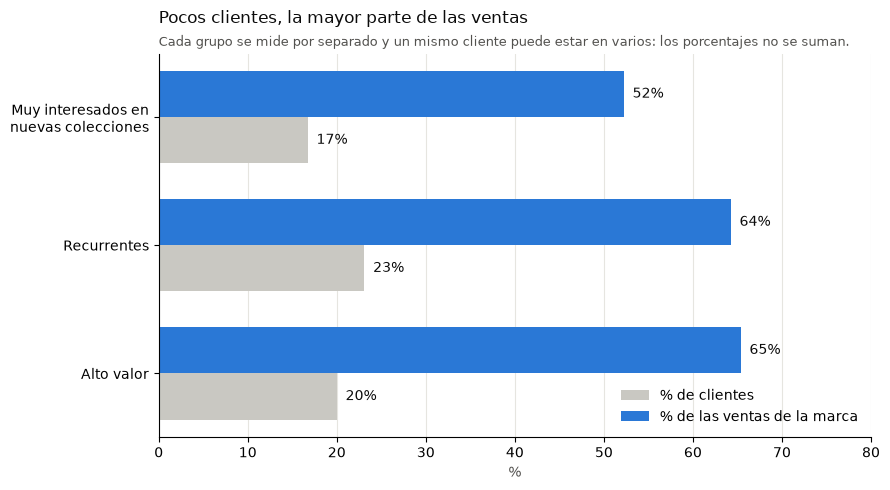

In [34]:
def pct(m):
    """% de clientes y % de ventas de la marca de un grupo."""
    return m.mean() * 100, clientes.loc[m, "venta_total"].sum() / total_marca * 100

grupos = {
    "Muy interesados en\nnuevas colecciones": es_novedad,
    "Recurrentes": es_recurrente,
    "Alto valor": es_alto
}
resumen = pd.DataFrame([pct(m) for m in grupos.values()], index=list(grupos), columns=["% clientes", "% ventas"])

y = range(len(resumen))
alto = 0.36
fig, ax = plt.subplots(figsize=(9, 5))
b1 = ax.barh([i + alto / 2 for i in y], resumen["% clientes"], height=alto, color="#c9c8c2", label="% de clientes")
b2 = ax.barh([i - alto / 2 for i in y], resumen["% ventas"], height=alto, color="#2a78d6", label="% de las ventas de la marca")

for barras in (b1, b2):
    for b in barras:
        ax.text(b.get_width() + 1, b.get_y() + b.get_height() / 2, f"{b.get_width():.0f}%",
                va="center", fontsize=10, color="#0b0b0b")

ax.set_yticks(list(y), resumen.index)
ax.invert_yaxis()
ax.set_xlim(0, 80)
ax.set_title("Pocos clientes, la mayor parte de las ventas", loc="left", fontsize=12, color="#0b0b0b", pad=22)
ax.text(0, 1.02, "Cada grupo se mide por separado y un mismo cliente puede estar en varios: los porcentajes no se suman.",
        transform=ax.transAxes, fontsize=9, color="#52514e")
ax.set_xlabel("%", color="#52514e")
ax.legend(frameon=False, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGS / "resumen_tres_preguntas.png", dpi=200, bbox_inches="tight")
plt.show()

- Muy interesados en nuevas colecciones: 17% de los clientes, 52% de las ventas.
- Recurrentes: 23% de los clientes, 64% de las ventas.
- Alto valor: 20% de los clientes, 65% de las ventas.

Los tres grupos se superponen en buena parte: el núcleo del negocio es un mismo conjunto de clientes que compra seguido, gasta más y responde a las novedades. Los arquetipos de la siguiente sección permiten ver cómo se combinan estas características.

          clientes      ventas  % clientes  % ventas
n_grupos                                            
0             1904   7243439.4        66.2      17.1
1              401   5663759.1        13.9      13.4
2              397  11813150.8        13.8      28.0
3              175  17527455.0         6.1      41.5


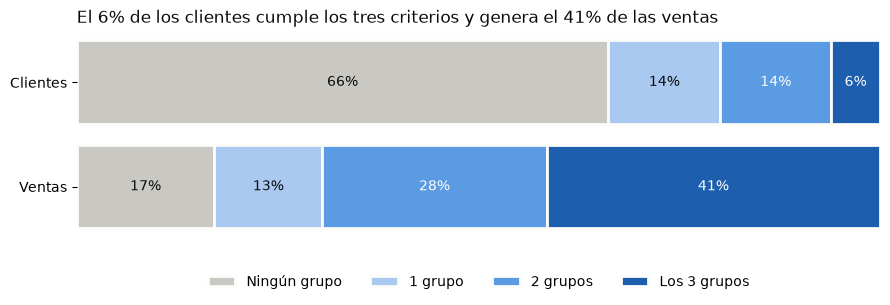

In [38]:
clientes["n_grupos"] = es_novedad.astype(int) + es_recurrente.astype(int) + es_alto.astype(int)

por_n = clientes.groupby("n_grupos").agg(clientes=("venta_total", "size"), ventas=("venta_total", "sum"))
por_n["% clientes"] = por_n["clientes"] / por_n["clientes"].sum() * 100
por_n["% ventas"] = por_n["ventas"] / por_n["ventas"].sum() * 100
print(por_n.round(1).to_string())

etiquetas = {0: "Ningún grupo", 1: "1 grupo", 2: "2 grupos", 3: "Los 3 grupos"}
colores = {0: "#c9c8c2", 1: "#a9c9f0", 2: "#5b9be3", 3: "#1d5fae"}

fig, ax = plt.subplots(figsize=(9, 3.2))
for fila, col in enumerate(["% clientes", "% ventas"]):
    izq = 0
    for n in por_n.index:
        v = por_n.loc[n, col]
        ax.barh(fila, v, left=izq, color=colores[n], edgecolor="#fcfcfb", linewidth=2,
                label=etiquetas[n] if fila == 0 else None)
        if v >= 5:
            ax.text(izq + v / 2, fila, f"{v:.0f}%", ha="center", va="center", fontsize=10,
                    color="#fcfcfb" if n >= 2 else "#0b0b0b")
        izq += v

ax.set_yticks([0, 1], ["Clientes", "Ventas"])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("El 6% de los clientes cumple los tres criterios y genera el 41% de las ventas",
             loc="left", fontsize=12, color="#0b0b0b")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)
ax.set_xticks([])

plt.tight_layout()
plt.savefig(FIGS / "resumen_nucleo.png", dpi=200, bbox_inches="tight")
plt.show()

Para no contar dos veces a un mismo cliente, cada uno se clasifica según cuántos de los tres criterios cumple (muy interesado en novedades, recurrente y de alto valor). Así las categorías no se superponen y suman 100%:

| Criterios que cumple | % de clientes | % de las ventas |
|---|---|---|
| Los 3 | 6,1% (175) | 41,5% |
| 2 | 13,8% (397) | 28,0% |
| 1 | 13,9% (401) | 13,4% |
| Ninguno | 66,2% (1.904) | 17,1% |

175 clientes, el 6%, generan el 41,5% de las ventas: es el núcleo del negocio. Sumando a quienes cumplen dos criterios, el 20% de los clientes concentra cerca del 70% de las ventas. En el otro extremo, dos de cada tres clientes no cumplen ningún criterio y aportan el 17%.


## 7. Arquetipos de clientes

Los arquetipos combinan lo calculado en las tres preguntas (valor, recurrencia y novedad) con la antigüedad del cliente. Cada cliente se asigna a un solo arquetipo: las reglas se evalúan en orden y gana la primera que se cumple.

| # | Arquetipo | Regla |
|---|---|---|
| 1 | Fans de la marca | Alto valor y recurrente |
| 2 | Valiosos en riesgo | Alto valor, pero no recurrente en el último año |
| 3 | Leales en crecimiento | Recurrente, pero no de alto valor |
| 4 | Nuevos | Primera compra en los últimos 6 meses |
| 5 | Ocasionales | Compró en los últimos 6 meses, pero con baja frecuencia |
| 6 | Dormidos | Más de 6 meses sin comprar |

¿Por qué 6 grupos? Cada uno requiere una acción distinta del CRM: con menos grupos se mezclarían clientes que necesitan mensajes diferentes, y con más aparecerían grupos pequeños sin una acción propia. El interés por las nuevas colecciones no define un arquetipo: se mide dentro de cada uno, para decidir a quién invitar a los lanzamientos.

La diferencia entre ocasionales y dormidos es la recencia: los ocasionales siguen activos (compraron en los últimos 6 meses) y los dormidos llevan una temporada completa sin volver. El corte de 180 días se apoya en la distribución de días entre compras: el 75% de las recompras ocurre antes de los 60 días.

In [40]:
import numpy as np

ultima = compras.groupby("customer_id")["fecha"].max()
primera = compras.groupby("customer_id")["fecha"].min()
clientes["dias_sin_comprar"] = (FECHA_CORTE - ultima).dt.days
clientes["nuevo"] = primera > FECHA_CORTE - pd.Timedelta(days=180)

ordenes_cli = ventas_cli.drop_duplicates("order_id")
clientes["pct_online"] = ordenes_cli.groupby("customer_id")["canal"].apply(lambda s: (s == "online").mean() * 100)

In [41]:
alto = clientes["nivel_valor"].eq("Alto valor")
rec = clientes["nivel_recurrencia"].eq("Recurrente")

condiciones = [
    alto & rec,
    alto & ~rec,
    ~alto & rec,
    clientes["nuevo"],
    clientes["dias_sin_comprar"] > 180,
]
nombres = ["Fans de la marca", "Valiosos en riesgo", "Leales en crecimiento", "Nuevos", "Dormidos"]
orden = nombres[:4] + ["Ocasionales", "Dormidos"]

clientes["arquetipo"] = pd.Categorical(np.select(condiciones, nombres, default="Ocasionales"), categories=orden)
clientes["arquetipo"].value_counts().reindex(orden)

arquetipo
Fans de la marca          443
Valiosos en riesgo        132
Leales en crecimiento     221
Nuevos                    218
Ocasionales               619
Dormidos                 1244
Name: count, dtype: int64

In [43]:
reales = customers[~customers["cuenta_interna"]]
sin_compra = reales[~reales["customer_id"].isin(clientes.index)]

print("Clientes registrados:", len(customers))
print("  - cuentas internas:", customers["cuenta_interna"].sum())
print("  = clientes reales:", len(reales))
print("  - con al menos una compra (arquetipos):", len(clientes))
print("  = registrados sin ninguna compra:", len(sin_compra))

print("\nSuma de los arquetipos:", clientes["arquetipo"].value_counts().sum())
print("Clientes sin arquetipo:", clientes["arquetipo"].isna().sum())

assert clientes["arquetipo"].notna().all()
assert clientes["arquetipo"].value_counts().sum() == len(clientes)
assert len(clientes) + len(sin_compra) == len(reales)

Clientes registrados: 3005
  - cuentas internas: 16
  = clientes reales: 2989
  - con al menos una compra (arquetipos): 2877
  = registrados sin ninguna compra: 112

Suma de los arquetipos: 2877
Clientes sin arquetipo: 0


**Verificación de la asignación**

Cada cliente queda en un solo arquetipo: las reglas se revisan en orden y el cliente se queda en la primera que cumple. Por eso nadie queda repetido ni sin asignar. Los seis arquetipos suman 2.877 clientes (443 + 132 + 221 + 218 + 619 + 1.244), exactamente el número de clientes que han comprado.

¿Por qué 2.877 y no los 3.005 de la base de clientes?

| | Clientes |
|---|---|
| Registrados en la base de clientes | 3.005 |
| − Cuentas de la propia marca (empleados y mostrador), que no son clientes | 16 |
| = Clientes de la marca | 2.989 |
| − Clientes que han comprado al menos una vez (se agrupan en arquetipos) | 2.877 |
| = Clientes que se registraron pero nunca compraron | 112 |

Los 112 clientes que nunca compraron no entran en los arquetipos, porque los arquetipos se basan en cómo compra cada cliente y ellos no tienen compras. Aun así, forman un grupo útil para el CRM, con un objetivo claro: lograr su primera compra.

### Perfil de cada arquetipo

Para describir cada arquetipo se resume cómo compran sus clientes: cuánto pesan en las ventas, cuánto gastan, cada cuánto compran, cuánto llevan por compra, hace cuánto no compran, qué tanto les interesan las nuevas colecciones y por qué canal compran.

In [45]:
clientes["muy_interesado"] = clientes["nivel_novedad"].eq("Muy interesado")

perfil = (clientes.groupby("arquetipo", observed=True)
          .agg(clientes=("venta_total", "size"),
               venta_total=("venta_total", "sum"),
               gasto_prom=("venta_total", "mean"),
               compras_12m=("compras_12m", "mean"),
               ticket_prom=("ticket_prom", "mean"),
               dias_sin_comprar=("dias_sin_comprar", "median"),
               pct_muy_interesado=("muy_interesado", "mean"),
               pct_online=("pct_online", "mean")))

perfil["% clientes"] = perfil["clientes"] / perfil["clientes"].sum() * 100
perfil["% ventas marca"] = perfil["venta_total"] / total_marca * 100
perfil["pct_muy_interesado"] *= 100
perfil.drop(columns="venta_total").round(1)

,clientes,gasto_prom,compras_12m,ticket_prom,dias_sin_comprar,pct_muy_interesado,pct_online,% clientes,% ventas marca
arquetipo,,,,,,,,,
Fans de la marca,443,57914.3,9.1,2523.2,21.0,39.5,52.6,15.4,57.0
Valiosos en riesgo,132,28576.0,3.8,2528.3,30.0,95.5,81.7,4.6,8.4
Leales en crecimiento,221,14799.0,7.1,1246.2,28.0,1.4,53.7,7.7,7.3
Nuevos,218,2698.7,1.6,1327.5,84.5,0.0,51.4,7.6,1.3
Ocasionales,619,8168.1,2.5,1633.0,76.0,25.7,64.1,21.5,11.2
Dormidos,1244,3138.9,0.4,1240.5,446.0,1.4,49.5,43.2,8.7


### Descripción de los arquetipos

| Arquetipo | Clientes | % ventas | Cómo es | Acción de CRM |
|---|---|---|---|---|
| Fans de la marca | 443 (15%) | 57% | Compran 9 veces al año, ticket alto (2.523 MXN), última compra hace 3 semanas. 4 de cada 10 son muy interesados en novedades. Compran online y en tienda por igual. | Cuidarlos: programa de lealtad, acceso anticipado a colecciones y trato preferente. |
| Cazadores de lanzamientos | 132 (5%) | 8% | Compran pocas veces al año (3,8), pero con ticket alto y casi siempre en los lanzamientos (95% muy interesados). El 82% compra online. | Avisarles primero de cada lanzamiento por email: preventa online y novedades. |
| Leales en crecimiento | 221 (8%) | 7% | Compran seguido (7 veces al año), pero con el ticket más bajo (1.246 MXN) y casi sin interés por las novedades. | Subir el ticket: combinaciones de prendas y venta cruzada. |
| Nuevos | 218 (8%) | 1% | Primera compra en los últimos 6 meses; 1,6 compras en promedio. | Lograr la segunda compra: bienvenida y recomendaciones según su primera compra. |
| Ocasionales | 619 (22%) | 11% | Compran 2 o 3 veces al año y siguen activos (última compra hace 2,5 meses). Uno de cada cuatro responde a las novedades. | Darles motivos para volver: comunicación de temporada y de lanzamientos. |
| Dormidos | 1.244 (43%) | 9% | Más de un año sin comprar (446 días de mediana). | Una campaña de reactivación de bajo costo; si no responden, dejar de invertir en ellos. |

**Hallazgo:** la hipótesis inicial era que los clientes de alto valor que no compran con frecuencia estaban en riesgo de perderse. Los datos lo descartan: su última compra fue hace apenas 30 días. Son clientes que compran casi exclusivamente en los lanzamientos y por el canal online, y requieren una estrategia distinta a la de retención.